# Run the Sentinel-3 computation

This notebook runs `compute.py` from its own directory, shows Matplotlib output in the notebook, and displays the saved final figure. The computation invokes Flick-AccuRT several times and may take a while.

In [1]:
%matplotlib inline

import os
import shutil
import sys
from pathlib import Path
from IPython.display import Image, display

project_dir = Path.cwd()
script = project_dir / "compute.py"
if not script.is_file():
    raise FileNotFoundError(
        f"Could not find {script}. Start Jupyter in the directory containing compute.py."
    )

# Load Flick directly from this repository checkout.
repository_dir = project_dir.parents[2]
python_module_dir = repository_dir / "python_script"
flick_module = python_module_dir / "flick.py"
if not flick_module.is_file():
    raise FileNotFoundError(f"Could not find the Flick module at {flick_module}")
sys.path.insert(0, str(python_module_dir))
os.environ["PATH"] = os.pathsep.join(
    [str(repository_dir), str(Path.home() / ".local" / "bin"), os.environ.get("PATH", "")]
)

import flick

print(f"Working directory: {project_dir}")
print(f"Flick module: {flick.__file__}")
print(f"Flick launcher: {shutil.which('flick')}")
print(f"Running: {script.name}")

Working directory: /Users/borgehamre/code/flick_github/Example/accurt_calls/sentinel
Flick module: /Users/borgehamre/code/flick_github/python_script/flick.py
Flick launcher: /Users/borgehamre/code/flick_github/flick
Running: compute.py


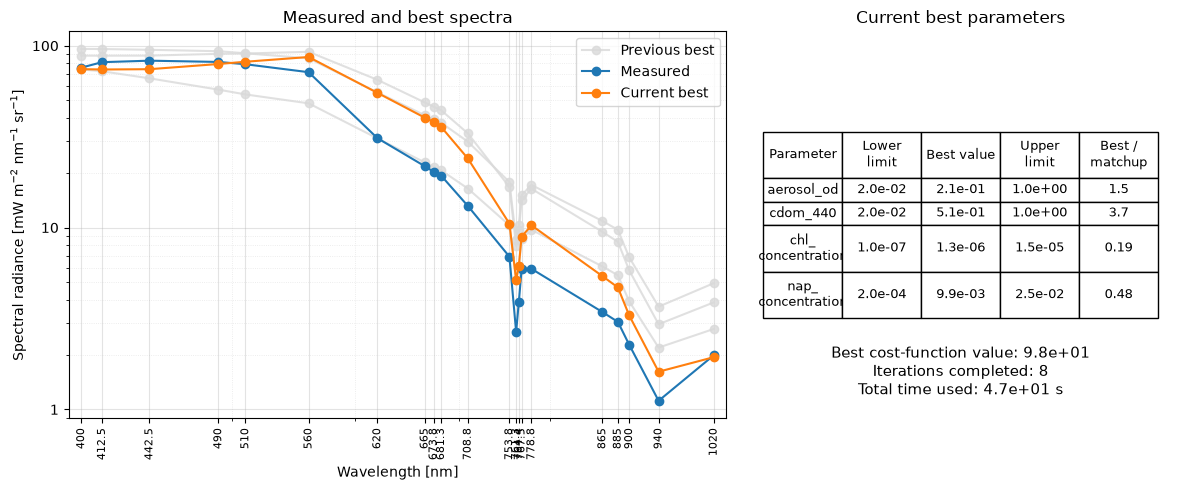

<Figure size 640x480 with 0 Axes>

In [2]:
%run compute.py

## Saved optimization result

`compute.py` saves a 300-DPI copy of the final plot. The cell below displays that exact file.

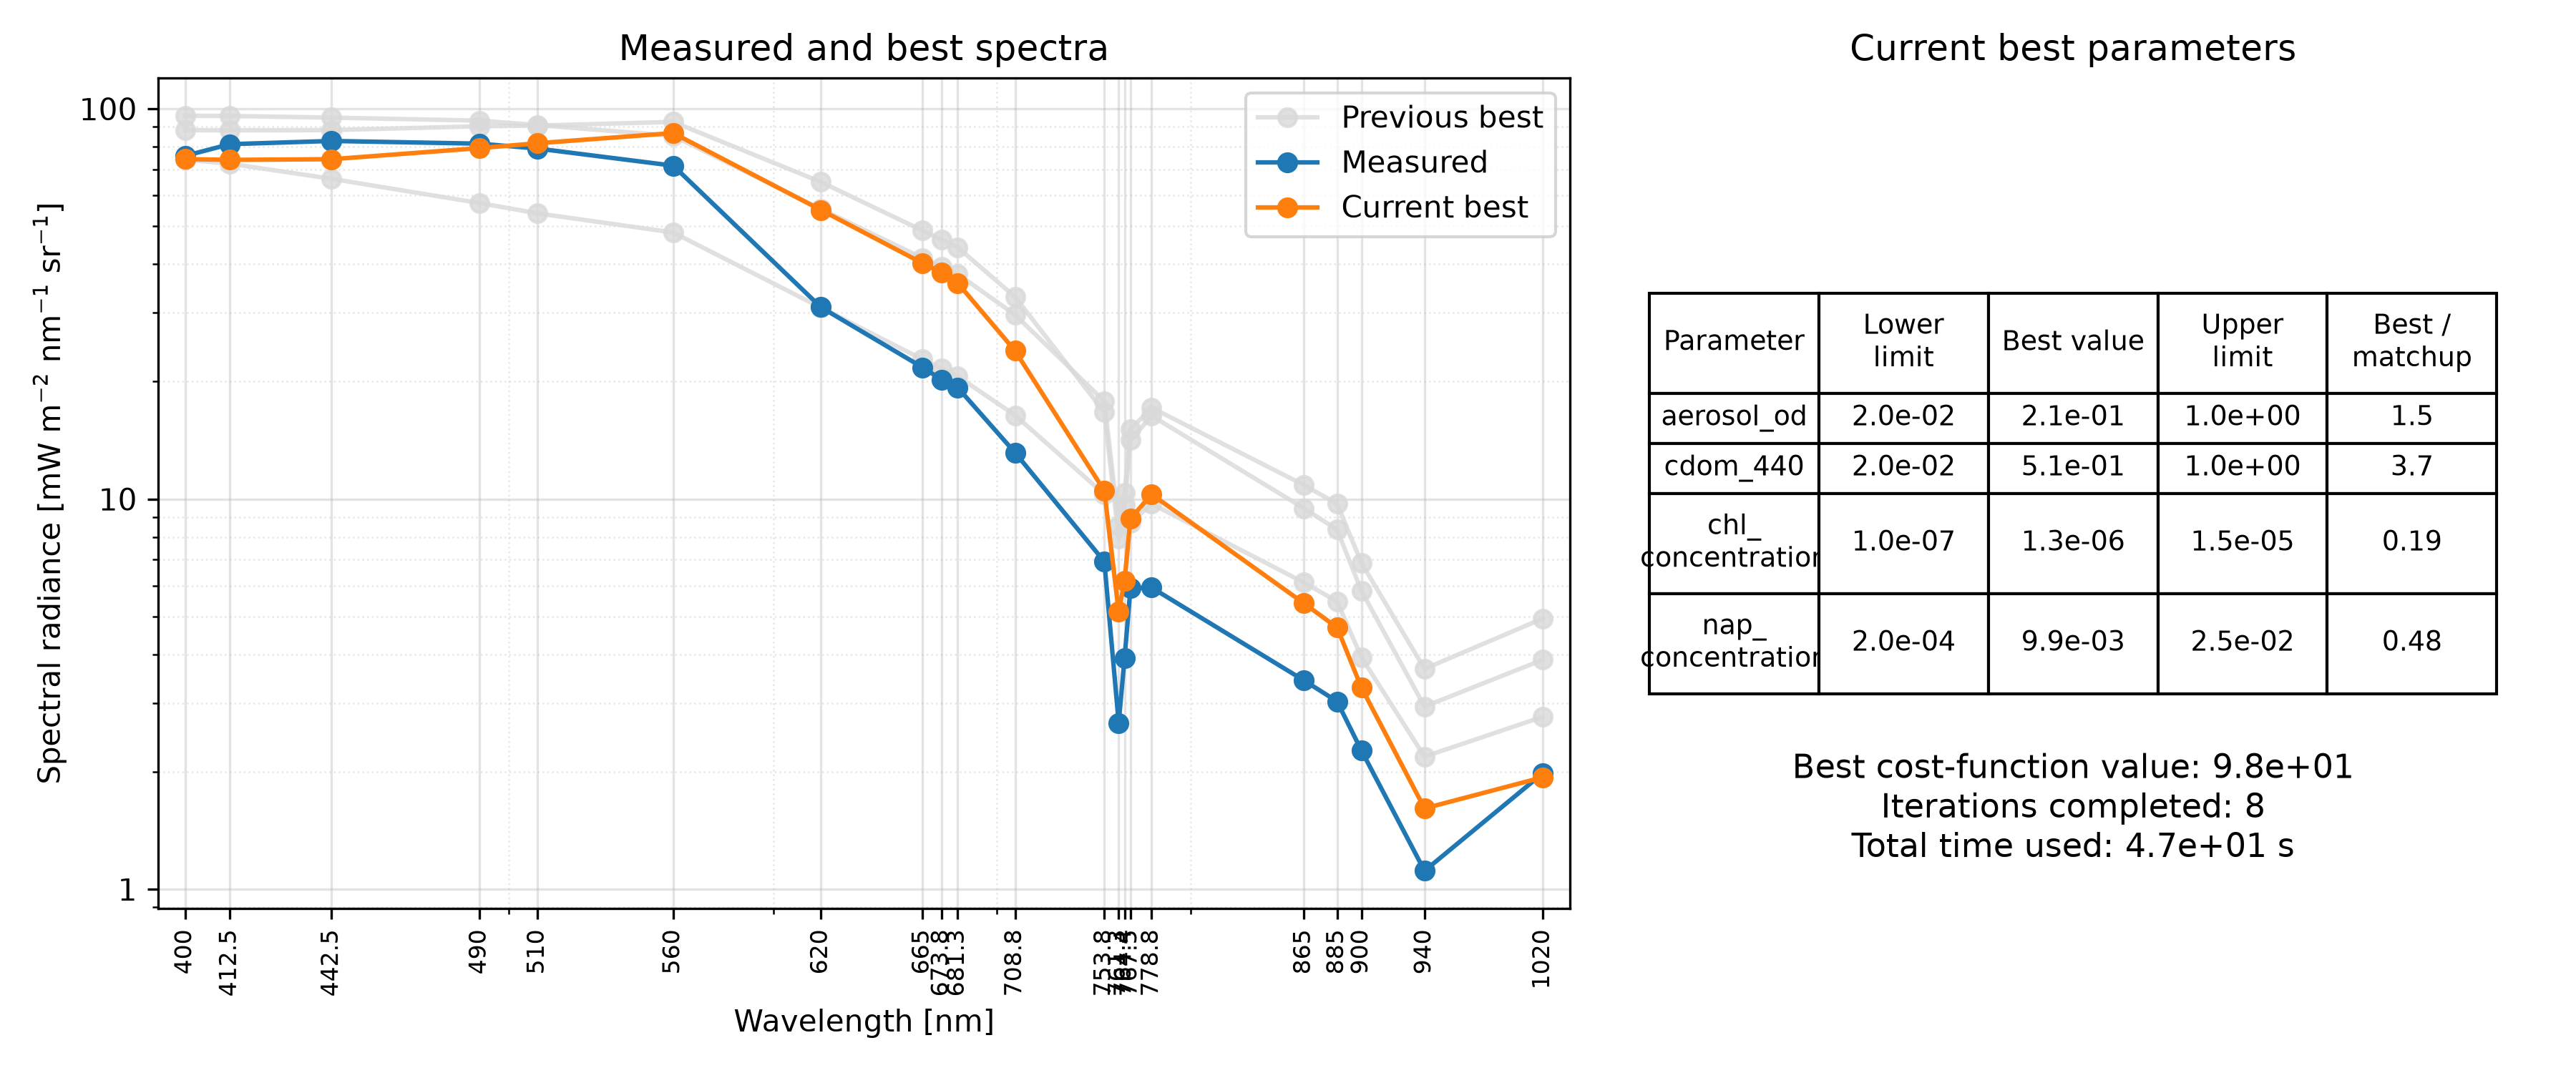

In [3]:
result_plot = project_dir / "output" / "optimization_result.png"
if result_plot.is_file():
    display(Image(filename=str(result_plot)))
else:
    print(f"No saved plot found at {result_plot}")

## Best fitted parameters

The final parameter values are also written by `compute.py`.

In [7]:
parameter_file = project_dir / "output" / "best_parameter_values.txt"
if parameter_file.is_file():
    print(parameter_file.read_text())
else:
    print(f"No parameter file found at {parameter_file}")

1	 0.2234
2	 0.1111
3	 5.623e-06
4	 0.008267

